# 04 Cost-based threshold analysis (training set only)

Extension: how sensitivity, specificity and expected cost change with the classification threshold for the model selected in notebook 03, and how sensitive the best operating point is to the assumed cost ratio. Everything uses the out-of-fold CV probabilities from the training set. The test set is not loaded.

## Decisions fixed before looking at any results

- **Costs** (from notebook 03): $c_{FP} = 1$ (one wasted tasting), $c_{FN} = r$ (lost premium margin), base case $r = 3$. Expected cost per wine $= (FP + r \cdot FN)/n$.
- **Cost ratios for the sensitivity check:** $r \in \{1/3, 1/2, 1, 2, 3, 5, 10\}$. Ratios below 1 cover the other framing (for example, choosing wines for a premium shelf), where a false positive costs more.
- **Operating point rule:** the threshold on a 0.01 grid that minimises the pooled out-of-fold expected cost at $r = 3$. The theoretical $t^* = 1/(1+r)$ is reported alongside it. $t^*$ is only optimal if the predicted probabilities are calibrated, so any gap between the two is informative.
- **Comparison policies:** threshold 0.5, threshold $t^*$, and the two no-model policies *send every batch to the panel* (cost $= 1 - \pi$ per wine) and *send none* (cost $= r\pi$), where $\pi$ is the share of good wines.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

from wine_utils import expected_cost, COST_RATIOS, C_FN_BASE, C_FP

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

def ratio_label(r):
    return f'1/{1 / r:g}' if r < 1 else f'{r:g}'

spec = json.load(open('results/selected_model.json'))
oof = pd.read_csv('results/oof_probabilities.csv', index_col=0)
y, prob, fold = oof['y'].values, oof[spec['name']].values, oof['fold'].values
pi = y.mean()
grid = np.round(np.arange(0.01, 1.00, 0.01), 2)
print('Selected model:', spec['name'], '| share good =', round(pi, 3))

Selected model: Logistic (all 11) | share good = 0.208


## Sensitivity and specificity against the threshold

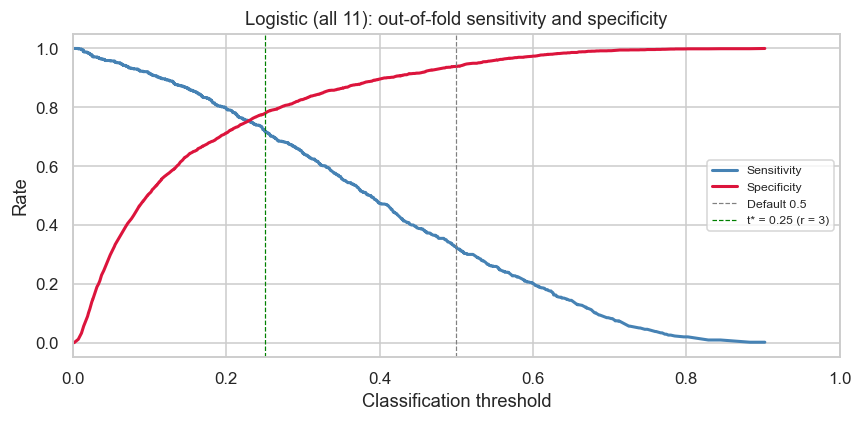

In [2]:
fpr, tpr, thr = roc_curve(y, prob)
fpr, tpr, thr = fpr[1:], tpr[1:], thr[1:]   # drop the artificial infinite threshold

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, tpr, lw=2, color='steelblue', label='Sensitivity')
ax.plot(thr, 1 - fpr, lw=2, color='crimson', label='Specificity')
ax.axvline(0.5, color='grey', ls='--', lw=0.8, label='Default 0.5')
ax.axvline(1 / (1 + C_FN_BASE), color='green', ls='--', lw=0.8,
           label=f't* = {1 / (1 + C_FN_BASE):.2f} (r = {C_FN_BASE})')
ax.set(xlim=(0, 1), xlabel='Classification threshold', ylabel='Rate',
       title=f'{spec["name"]}: out-of-fold sensitivity and specificity')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Expected cost against the threshold, for each cost ratio

Costs are divided by the cheaper of the two no-model policies, so a value below 1 means that screening with the model is cheaper than the best policy available without one.

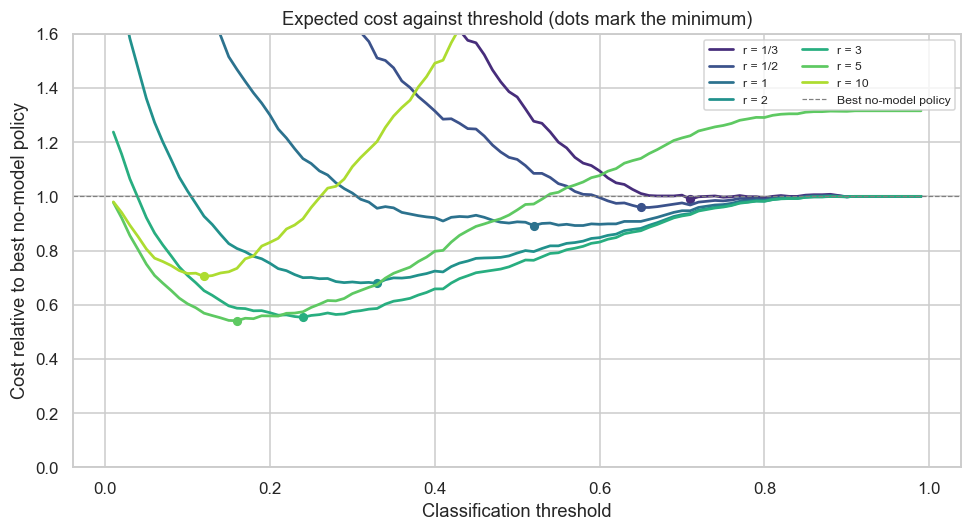

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = sns.color_palette('viridis', len(COST_RATIOS))
for r, col in zip(COST_RATIOS, colors):
    trivial = min(1 - pi, r * pi)
    cost = np.array([expected_cost(y, prob, t, r) for t in grid]) / trivial
    ax.plot(grid, cost, color=col, lw=1.8, label=f'r = {ratio_label(r)}')
    ax.plot(grid[cost.argmin()], cost.min(), 'o', color=col, ms=5)
ax.axhline(1, color='grey', ls='--', lw=0.8, label='Best no-model policy')
ax.set(xlabel='Classification threshold', ylabel='Cost relative to best no-model policy',
       title='Expected cost against threshold (dots mark the minimum)', ylim=(0, 1.6))
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## Sensitivity check across cost ratios

For each ratio: the theoretical $t^*$, the empirically optimal threshold on the pooled out-of-fold probabilities, the spread of the optimal threshold when it is found separately in each of the 10 folds, and the range of thresholds whose cost stays within 5% of the minimum (how flat the cost curve is near its minimum).

In [4]:
def best_threshold(y_, p_, r):
    costs = np.array([expected_cost(y_, p_, t, r) for t in grid])
    return grid[costs.argmin()], costs

rows = []
for r in COST_RATIOS:
    t_opt, costs = best_threshold(y, prob, r)
    per_fold = [best_threshold(y[fold == k], prob[fold == k], r)[0] for k in np.unique(fold)]
    flat = grid[costs <= 1.05 * costs.min()]
    trivial = min(1 - pi, r * pi)
    rows.append({
        'r = c_FN/c_FP': r,
        't* theory': 1 / (1 + r),
        't optimal (pooled)': t_opt,
        'fold optimum mean': np.mean(per_fold),
        'fold optimum SD': np.std(per_fold, ddof=1),
        'within 5% of min': f'{flat.min():.2f}-{flat.max():.2f}',
        'cost @ t optimal': costs.min(),
        'cost @ t*': expected_cost(y, prob, 1 / (1 + r), r),
        'cost @ 0.5': expected_cost(y, prob, 0.5, r),
        'best no-model cost': trivial,
        'saving vs no-model': 1 - costs.min() / trivial,
    })
sens = pd.DataFrame(rows)
sens.round(3)

,r = c_FN/c_FP,t* theory,t optimal (pooled),fold optimum mean,fold optimum SD,within 5% of min,cost @ t optimal,cost @ t*,cost @ 0.5,best no-model cost,saving vs no-model
0,0.333,0.750,0.71,0.718,0.116,0.64-0.99,0.069,0.069,0.095,0.069,0.011
1,0.500,0.667,0.65,0.671,0.096,0.59-0.99,0.100,0.100,0.118,0.104,0.041
2,1.000,0.500,0.52,0.481,0.108,0.37-0.68,0.186,0.189,0.189,0.208,0.108
3,2.000,0.333,0.33,0.327,0.051,0.23-0.38,0.283,0.283,0.330,0.417,0.321
4,3.000,0.250,0.24,0.270,0.090,0.18-0.31,0.346,0.350,0.470,0.625,0.446
5,5.000,0.167,0.16,0.173,0.047,0.13-0.21,0.428,0.432,0.752,0.792,0.459
6,10.000,0.091,0.12,0.122,0.031,0.09-0.16,0.558,0.573,1.456,0.792,0.295


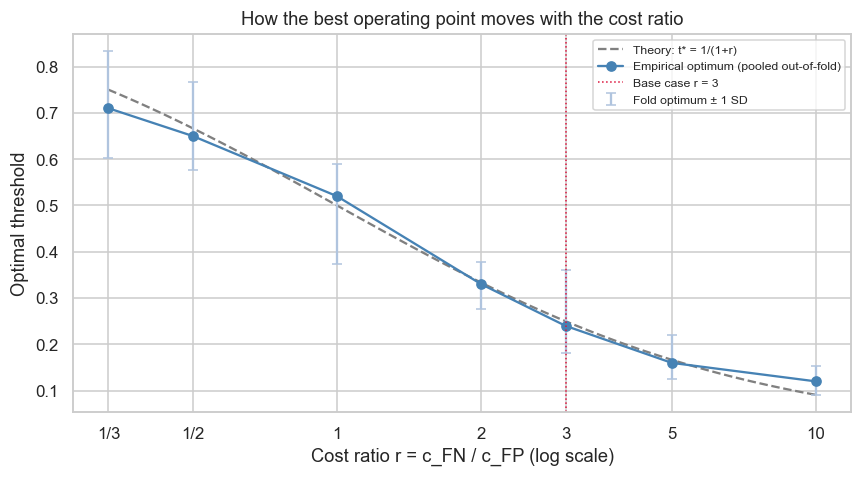

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
r_fine = np.logspace(np.log10(1/3), 1, 100)
ax.plot(r_fine, 1 / (1 + r_fine), color='grey', ls='--', label='Theory: t* = 1/(1+r)')
ax.errorbar(sens['r = c_FN/c_FP'], sens['fold optimum mean'], yerr=sens['fold optimum SD'],
            fmt='none', ecolor='lightsteelblue', capsize=3, label='Fold optimum ± 1 SD')
ax.plot(sens['r = c_FN/c_FP'], sens['t optimal (pooled)'], 'o-', color='steelblue',
        label='Empirical optimum (pooled out-of-fold)')
ax.axvline(C_FN_BASE, color='crimson', ls=':', lw=1, label=f'Base case r = {C_FN_BASE}')
ax.set_xscale('log')
ax.set_xticks(COST_RATIOS, [ratio_label(r) for r in COST_RATIOS])
ax.set(xlabel='Cost ratio r = c_FN / c_FP (log scale)', ylabel='Optimal threshold',
       title='How the best operating point moves with the cost ratio')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Operating point (base case $r = 3$)

In [6]:
base = sens.loc[sens['r = c_FN/c_FP'] == C_FN_BASE].iloc[0]
t_op = float(base['t optimal (pooled)'])
pred = prob >= t_op
tp, fp = int(np.sum(pred & (y == 1))), int(np.sum(pred & (y == 0)))
fn, tn = int(np.sum(~pred & (y == 1))), int(np.sum(~pred & (y == 0)))

operating_point = {
    'model': spec['name'], 'cost_ratio': C_FN_BASE, 'threshold': t_op,
    'theoretical_threshold': 1 / (1 + C_FN_BASE),
    'cv_sensitivity': tp / (tp + fn), 'cv_specificity': tn / (tn + fp),
    'cv_cost_per_wine': float(base['cost @ t optimal']),
}
with open('results/operating_point.json', 'w') as f:
    json.dump(operating_point, f, indent=2)
operating_point

{'model': 'Logistic (all 11)',
 'cost_ratio': 3,
 'threshold': 0.24,
 'theoretical_threshold': 0.25,
 'cv_sensitivity': 0.7393939393939394,
 'cv_specificity': 0.7687400318979266,
 'cv_cost_per_wine': 0.34595959595959597}